<a href="https://colab.research.google.com/github/saieshkadam/creditdefault_prediction/blob/main/creditdefault_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ROC-AUC: 0.7110


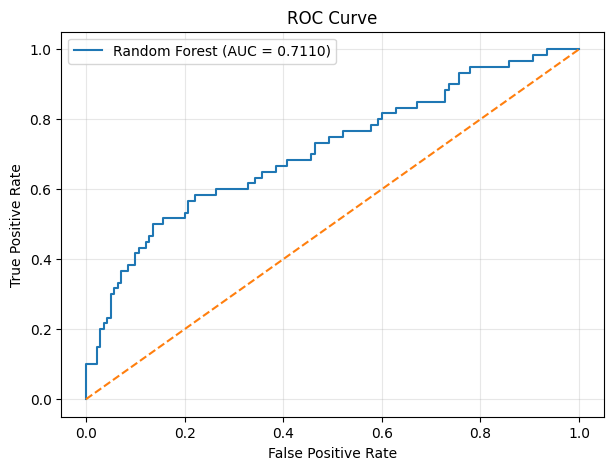

In [ ]:
!pip -q install imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

df = pd.read_csv("/content/german_credit_data.csv")
df = df.drop(columns=["Unnamed: 0"])
df["Risk"] = df["Risk"].map({"good": 0, "bad": 1})

X = df.drop(columns="Risk")
y = df["Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

def features(df):
    df = df.copy()
    df["Credit_per_month"] = df["Credit amount"] / df["Duration"]
    df["Credit_age_ratio"] = df["Credit amount"] / df["Age"]
    df["Duration_age_ratio"] = df["Duration"] / df["Age"]
    df["Age_group"] = pd.cut(
        df["Age"], [0,25,35,50,100],
        labels=["young","adult","middle_age","senior"]
    )
    df["Duration_group"] = pd.cut(
        df["Duration"], [0,12,24,36,60],
        labels=["short","medium","long","very_long"]
    )
    df["Credit_group"] = pd.cut(
        df["Credit amount"], [0,2000,5000,10000,np.inf],
        labels=["low","medium","high","very_high"]
    )
    return df

X_train = features(X_train)
X_test = features(X_test)

num = [
    "Age","Job","Credit amount","Duration",
    "Credit_per_month","Credit_age_ratio","Duration_age_ratio"
]

cat = [
    "Sex","Housing","Saving accounts","Checking account",
    "Purpose","Age_group","Duration_group","Credit_group"
]

pre = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler())
    ]), num),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="ignore"))
    ]), cat)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf = Pipeline([
    ("pre", pre),
    ("model", RandomForestClassifier(random_state=42))
])

rf_params = {
    "model__n_estimators": [300,500,700,900,1200],
    "model__max_depth": [3,4,5,6,8,10,12,15,20,None],
    "model__min_samples_split": [2,5,10,15,20,30],
    "model__min_samples_leaf": [1,2,4,6,8,10,15],
    "model__max_features": ["sqrt","log2",None],
    "model__criterion": ["gini","entropy"],
    "model__class_weight": [None,"balanced","balanced_subsample"],
    "model__bootstrap": [True]
}

rf_search = RandomizedSearchCV(
    rf,
    rf_params,
    n_iter=60,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

y_prob = rf_search.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, y_prob)

fpr, tpr, _ = roc_curve(y_test, y_prob)

print(f"ROC-AUC: {rf_auc:.4f}")

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {rf_auc:.4f})")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()